# Pattern Matching NILM

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

## Directories

In [2]:
base_dir = os.getcwd()
processed_data_dir = os.path.join(base_dir, 'processed_data')
results_dir = os.path.join(base_dir, 'results')

## Load Data

### Load Processed Data

In [3]:
processed_data_filepath = os.path.join(base_dir, 'processed_data', 'ampds_dataset.npz')
processed_data = np.load(processed_data_filepath)

# Check Data
print(f'Processed Data Items: {processed_data.files}')

Processed Data Items: ['electrical_quantities', 'appliance_names', 'agg_norm', 'apps_norm', 'agg_min', 'agg_max', 'apps_min', 'apps_max', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'window_length', 'stride']


In [4]:
print(f'Electrical Quantities: {processed_data['electrical_quantities']}')
print(f'Appliance Names: {processed_data['appliance_names']}')
print(f'Number Timestamps: {processed_data['T']}')

window_length = processed_data['window_length']
print(f'Window Length: {window_length}')
print(f'Stride: {processed_data['stride']}')

Electrical Quantities: ['P-agg' 'I-agg' 'Q-agg' 'S-agg']
Appliance Names: ['RSE' 'GRE' 'B1E' 'BME' 'CWE' 'DWE' 'EQE' 'FRE' 'HPE' 'OFE' 'UTE' 'WOE'
 'B2E' 'CDE' 'DNE' 'EBE' 'FGE' 'HTE' 'OUE' 'TVE']
Number Timestamps: 1000
Window Length: 30
Stride: 1


In [5]:
agg_norm = processed_data['agg_norm']
apps_norm = processed_data['apps_norm']
agg_column_labels = ["id", "time"] + processed_data["electrical_quantities"].tolist()
apps_column_labels = ["id", "time"] + processed_data["appliance_names"].tolist()

display(pd.DataFrame(
    agg_norm,
    columns=agg_column_labels)
    .head().style.format("{:.2f}").set_caption('Aggregate Measurements')
    .hide(axis='index'))

display(pd.DataFrame(
    apps_norm,
    columns=apps_column_labels)
    .head().style.format('{:.2f}').set_caption('Appliance-Level Measurements (P Only)')
    .hide(axis='index'))

id,time,P-agg,I-agg,Q-agg,S-agg
0.00,0.00,0.11,0.05,0.03,0.10
0.00,0.00,0.11,0.05,0.03,0.10
0.00,0.00,0.10,0.05,0.03,0.09
0.00,0.00,0.10,0.05,0.03,0.09
0.00,0.00,0.09,0.05,0.03,0.09


id,time,RSE,GRE,B1E,BME,CWE,DWE,EQE,FRE,HPE,OFE,UTE,WOE,B2E,CDE,DNE,EBE,FGE,HTE,OUE,TVE
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.67,0.29,0.01,0.27,1.00,0.00,0.74,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.00,0.00,0.74,0.00,0.00,0.33,0.36,0.01,0.27,1.00,0.00,0.74,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.67,0.36,0.01,0.27,1.00,0.00,0.01,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.61,0.29,0.01,0.27,1.00,0.00,0.00,0.00,0.97,0.00,0.00,0.02,0.00,0.00
0.00,0.00,0.00,0.50,0.00,0.74,0.00,0.00,0.61,0.29,0.01,0.27,1.00,0.00,0.01,0.00,1.00,0.00,0.00,0.02,0.00,0.00


In [6]:
print(f'Train/Val/Test Split: {processed_data['train_val_test_split']}')

train_indices = processed_data['train_indices']
val_indices = processed_data['val_indices']
test_indices = processed_data['test_indices']

print(f"Training Indices ({len(train_indices)} Total): {train_indices[:10]}...")
print(f"Validation Indices ({len(val_indices)} Total): {val_indices[:10]}...")
print(f"Testing Indices ({len(test_indices)} Total): {test_indices[:10]}...")

Train/Val/Test Split: [0.6 0.2 0.2]
Training Indices (513 Total): [500 851 559 845 471 564 954 535 753 729]...
Validation Indices (171 Total): [277 205 265 321 218 303 356 359 214 363]...
Testing Indices (171 Total): [ 64 156 117 155  69 120 129  53  27 131]...


### Load Distance Metrics

We previously calculated three distance metrics for each pair of windows: a template window from the training set and a query window from the validation or test set. We saved the results in a lookup dictionary. Each key is a `(template_idx, query_idx)` tuple, and its value is a `metrics` dictionary containing `feature_distance`, `pearson_correlation`, and `dtw_distance`. Here, we load the lookup and display a preview of its contents as a table.

In [9]:
distance_metrics_filepath = os.path.join(results_dir, 'combined_metric_lookup.pkl')
combined_metric_lookup = pd.read_pickle(distance_metrics_filepath)

In [11]:
combined_lookup_df = pd.DataFrame(
    [
        {
            "template idx": template_idx,
            "query idx": query_idx,
            "feature_distance": metrics["feature_distance"],
            "pearson_correlation": metrics["pearson_correlation"],
            "dtw_distance": metrics["dtw_distance"],
        }
        for (template_idx, query_idx), metrics in combined_metric_lookup.items()])

display(combined_lookup_df.head().style.set_caption('Consolidated Distance Metrics').hide(axis='index'))

template idx,query idx,feature_distance,pearson_correlation,dtw_distance
500,277,2.903394,0.270804,11.780360
851,277,0.330063,0.481780,4.230345
559,277,1.656885,0.258226,5.775319
845,277,1.259538,0.778396,2.950938
471,277,2.274879,0.784573,4.254507


## NILM Algorithm Performance

### Performance Metrics

The pattern-matching NILM algorithm aims to estimate power consumption for each appliance. To evaluate its performance, we compare the true appliance-level data with the predicted data. Before defining the performance metrics, note that each frame is a two-dimensional array. It contains a time-series for each appliance. Therefore, each metric function returns an array with one score per appliance, rather than a single score.

In [27]:
def compute_mae(frame1, frame2):
    return np.mean(np.abs(np.asarray(frame1) - np.asarray(frame2)), axis=0)

In [15]:
def compute_rmse(frame1, frame2):
    return np.sqrt(np.mean((frame1 - frame2) ** 2, axis=0))

In [16]:
def compute_sae(frame1, frame2):
    return np.sum(np.abs(np.asarray(frame1) - np.asarray(frame2)), axis=0)

Estimation accuracy measures how closely the estimated appliance power matches the measured power. A common NILM definition is:

$
\text{Accuracy}=1-\frac{\sum_k \sum_t |y_t^k -\hat y_t^k|}{2 \sum_k \sum_t y_t^k}
$

- $y$: Measured appliance power.
- $\hat{y}$: Estimated appliance power.
- $t$: Timestep.
- $k$: Appliance.

A score of 1 coresponds to a perfect match between true and predicted power. Lower scores indicate greater error. The function calculates EACC, taking extra care to avoid division by zero, in the case where true consumption is zero.

In [13]:
def compute_eacc(frame_true, frame_pred):

    abs_error = np.abs(frame_true - frame_pred)
    numerator = np.sum(abs_error, axis=0)
    denominator = 2 * np.sum(frame_true, axis=0)

    acc = np.ones_like(denominator, dtype=float)
    valid = denominator != 0

    acc[valid] = 1.0 - (numerator[valid] / denominator[valid])

    # Handle degenerate case where true consumption is zero
    zero_den = ~valid
    acc[zero_den] = np.where(numerator[zero_den] == 0, 1.0, 0.0)

    return acc.item() if np.ndim(acc) == 0 else acc

### Predict

In [17]:
def select_template(query_idx, combined_metric_lookup, method):
    
    metric_directions = {
        'feature_distance': 1,
        'pearson_correlation': -1,
        'dtw_distance': 1}

    candidates = [
        (template_idx, metrics[method])
        for (template_idx, candidate_query_idx), metrics in combined_metric_lookup.items()
        if candidate_query_idx == query_idx]

    direction = metric_directions[method]
    return min(candidates, key=lambda item: direction * item[1])[0]

In [22]:
def predict_frame(agg_norm, apps_norm, query_idx, window_length, combined_metric_lookup, method):
    best_template_idx = select_template(query_idx, combined_metric_lookup, method)
    return apps_norm[best_template_idx : best_template_idx + window_length]

`predict_time_series` builds a continuous appliance-level prediction by combining predictions from multiple query windows. `totals` stores summed predictions for each timestep and appliance. `counts` tracks how many windows contributed a prediction at each time step. For every `query_idx`, the function calls `predict_frame(...)`, adds its appliance values to `totals` and increments the corresponding `counts`. Where multiple windows predict the same time step, their values are averaged. The function starts from an array of all NaNs, and replaces the appliance columns only where predictions exist. That way, any uncovered time steps remain NaN. 

In [23]:
def predict_time_series(agg_norm, apps_norm, query_indices, window_length, combined_metric_lookup, method):

    start = max(0, query_indices.min())
    end = min(len(apps_norm), query_indices.max() + window_length)
    
    n_appliances = apps_norm.shape[1] - 2
    totals = np.zeros((end - start, n_appliances), dtype=float)
    counts = np.zeros(end - start, dtype=int)

    for query_idx in query_indices:
        
        prediction = predict_frame(agg_norm, apps_norm, query_idx, window_length, combined_metric_lookup, method)

        target_start = max(query_idx, start)
        target_end = min(query_idx + len(prediction), end)
        if target_start >= target_end:
            continue

        source_slice = slice(target_start - query_idx, target_end - query_idx)
        target_slice = slice(target_start - start, target_end - start)

        # Exclude template id/time columns; overlapping estimates are averaged.
        totals[target_slice] += prediction[source_slice, 2:]
        counts[target_slice] += 1

    covered = counts > 0
    result = np.full((end - start, apps_norm.shape[1]), np.nan)
    result[covered, 2:] = totals[covered] / counts[covered, None]

    return result

#### Method 1: Feature Distance

In [34]:
apps_pred = predict_time_series(agg_norm, apps_norm, test_indices, window_length, combined_metric_lookup, method='feature_distance')

In [35]:
# Copy the ground-truth rows corresponding to apps_pred, then keep rows with predictions.
pred_start = max(0, test_indices.min())
apps_true = apps_norm[pred_start:pred_start + len(apps_pred)].copy()

valid_rows = ~np.isnan(apps_pred[:, 2:]).any(axis=1)
apps_true = apps_true[valid_rows]
apps_pred = apps_pred[valid_rows]

In [36]:
mae = compute_mae(apps_true, apps_pred)
rmse = compute_rmse(apps_true, apps_pred)
sae = compute_sae(apps_true, apps_pred)
eacc = compute_eacc(apps_true, apps_pred)

# table of each metric for each appliance
feature_distance_results_metrics = pd.DataFrame({
    "Appliance": apps_column_labels[2:],
    "MAE": mae[2:],
    "RMSE": rmse[2:],
    "SAE": sae[2:],
    "EACC": eacc[2:]}).round({
    "MAE": 6,
    "RMSE": 6,
    "SAE": 6,
    "EACC": 6})

display(feature_distance_results_metrics.style
        .set_caption("Performance Metrics by Appliance")
        .hide(axis='index'))

Appliance,MAE,RMSE,SAE,EACC
RSE,0.023385,0.027052,4.677074,0.143711
GRE,0.295457,0.341323,59.091339,0.574882
B1E,0.000000,0.000000,0.000000,1.000000
BME,0.234735,0.422107,46.947049,0.521053
CWE,0.000194,0.001039,0.038837,0.000000
DWE,0.000000,0.000000,0.000000,1.000000
EQE,0.077250,0.146784,15.450099,0.936419
FRE,0.215027,0.296483,43.005341,0.806780
HPE,0.253812,0.292556,50.762483,0.556507
OFE,0.043156,0.097330,8.631259,0.520486


#### Method 2: Pearson Correlation

In [37]:
apps_pred = predict_time_series(agg_norm, apps_norm, test_indices, window_length, combined_metric_lookup, method='pearson_correlation')

In [38]:
# Copy the ground-truth rows corresponding to apps_pred, then keep rows with predictions.
pred_start = max(0, test_indices.min())
apps_true = apps_norm[pred_start:pred_start + len(apps_pred)].copy()

valid_rows = ~np.isnan(apps_pred[:, 2:]).any(axis=1)
apps_true = apps_true[valid_rows]
apps_pred = apps_pred[valid_rows]

In [39]:
mae = compute_mae(apps_true, apps_pred)
rmse = compute_rmse(apps_true, apps_pred)
sae = compute_sae(apps_true, apps_pred)
eacc = compute_eacc(apps_true, apps_pred)

# table of each metric for each appliance
pearson_correlation_results_metrics = pd.DataFrame({
    "Appliance": apps_column_labels[2:],
    "MAE": mae[2:],
    "RMSE": rmse[2:],
    "SAE": sae[2:],
    "EACC": eacc[2:]}).round({
    "MAE": 6,
    "RMSE": 6,
    "SAE": 6,
    "EACC": 6})

display(pearson_correlation_results_metrics.style
        .set_caption("Performance Metrics by Appliance")
        .hide(axis='index'))

Appliance,MAE,RMSE,SAE,EACC
RSE,0.042303,0.048477,8.460685,-0.549000
GRE,0.317264,0.374351,63.452900,0.543504
B1E,0.000000,0.000000,0.000000,1.000000
BME,0.322700,0.495852,64.540022,0.341572
CWE,0.002123,0.008321,0.424684,0.000000
DWE,0.000000,0.000000,0.000000,1.000000
EQE,0.088983,0.159269,17.796583,0.926763
FRE,0.347322,0.422056,69.464472,0.687900
HPE,0.365710,0.409324,73.142036,0.360986
OFE,0.047760,0.091002,9.552020,0.469332


#### Method 3: DTW Distance

In [40]:
apps_pred = predict_time_series(agg_norm, apps_norm, test_indices, window_length, combined_metric_lookup, method='dtw_distance')

In [41]:
# Copy the ground-truth rows corresponding to apps_pred, then keep rows with predictions.
pred_start = max(0, test_indices.min())
apps_true = apps_norm[pred_start:pred_start + len(apps_pred)].copy()

valid_rows = ~np.isnan(apps_pred[:, 2:]).any(axis=1)
apps_true = apps_true[valid_rows]
apps_pred = apps_pred[valid_rows]

In [42]:
mae = compute_mae(apps_true, apps_pred)
rmse = compute_rmse(apps_true, apps_pred)
sae = compute_sae(apps_true, apps_pred)
eacc = compute_eacc(apps_true, apps_pred)

# table of each metric for each appliance
dtw_distance_results_metrics = pd.DataFrame({
    "Appliance": apps_column_labels[2:],
    "MAE": mae[2:],
    "RMSE": rmse[2:],
    "SAE": sae[2:],
    "EACC": eacc[2:]}).round({
    "MAE": 6,
    "RMSE": 6,
    "SAE": 6,
    "EACC": 6})

display(dtw_distance_results_metrics.style
        .set_caption("Performance Metrics by Appliance")
        .hide(axis='index'))

Appliance,MAE,RMSE,SAE,EACC
RSE,0.028111,0.037412,5.622151,-0.029315
GRE,0.289888,0.344088,57.977580,0.582895
B1E,0.000000,0.000000,0.000000,1.000000
BME,0.207694,0.396035,41.538731,0.576228
CWE,0.000000,0.000000,0.000000,1.000000
DWE,0.000000,0.000000,0.000000,1.000000
EQE,0.084959,0.153350,16.991709,0.930075
FRE,0.192752,0.228863,38.550397,0.826795
HPE,0.104902,0.169574,20.980316,0.816703
OFE,0.042759,0.098050,8.551745,0.524903


#### Summary

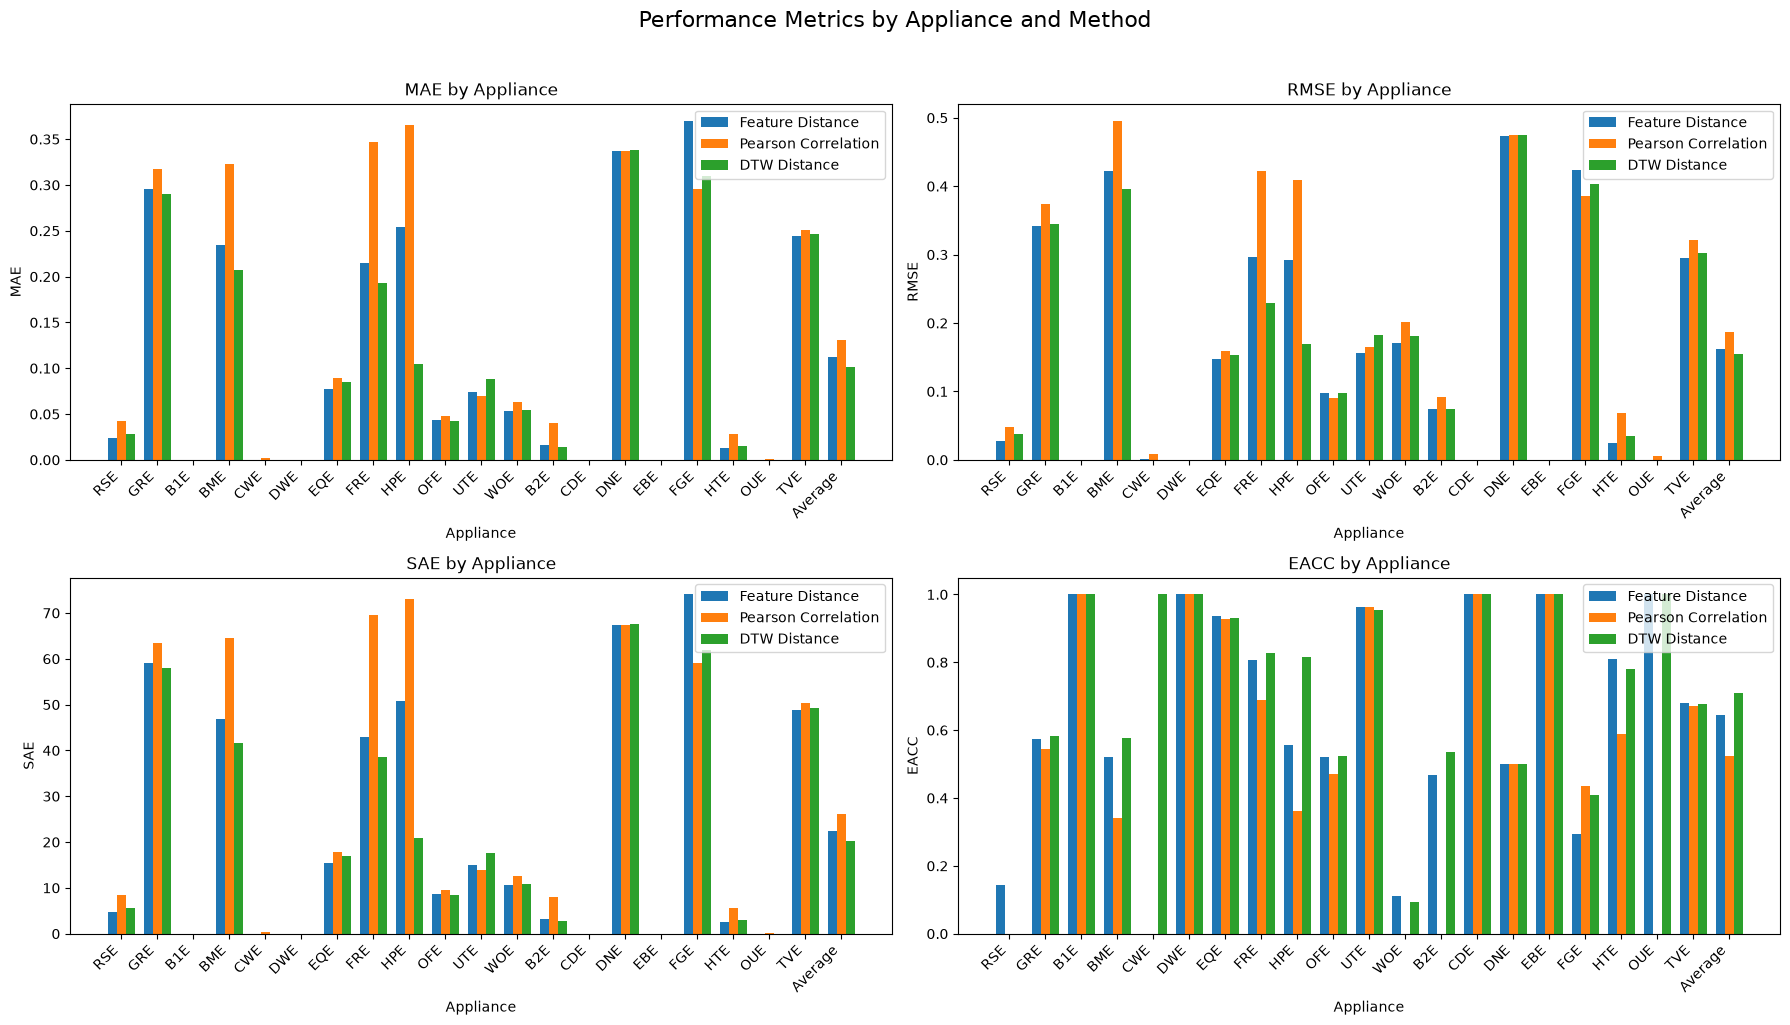

In [45]:
# Clip negative EACC values and add an across-appliance average for each metric.
method_tables = {
    "Feature Distance": feature_distance_results_metrics,
    "Pearson Correlation": pearson_correlation_results_metrics,
    "DTW Distance": dtw_distance_results_metrics,
}

metric_names = ["MAE", "RMSE", "SAE", "EACC"]
appliance_order = method_tables["Feature Distance"]["Appliance"].tolist()
plot_appliances = appliance_order + ["Average"]

fig, axes = plt.subplots(2, 2, figsize=(18, 10), sharex=False)
axes = axes.flatten()
x = np.arange(len(plot_appliances))
width = 0.25

for ax, metric in zip(axes, metric_names):
    for i, (method_name, df) in enumerate(method_tables.items()):
        vals = (
            df.set_index("Appliance")[metric]
            .reindex(appliance_order)
            .to_numpy()
        )

        if metric == "EACC":
            vals = np.clip(vals, 0, None)

        vals = np.append(vals, np.mean(vals))
        ax.bar(x + (i - 1) * width, vals, width=width, label=method_name)

    ax.set_title(f"{metric} by Appliance")
    ax.set_xlabel("Appliance")
    ax.set_ylabel(metric)
    ax.set_xticks(x)
    ax.set_xticklabels(plot_appliances, rotation=45, ha="right")
    ax.legend(loc="best")

fig.suptitle("Performance Metrics by Appliance and Method", fontsize=16, y=1.02)
fig.tight_layout()
plt.show()